<a href="https://colab.research.google.com/github/Madihasafi/ITC-300-Data-Visualization-/blob/main/Israr_Ahmad_Arghandiwal_%26_Madiha_Safi%2C_Final_Project_ITC_300_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITC 300 – Data Visualization Final Course Project

**Project Title**: Socioeconomic and Geographic Exploratory Analysis of California Housing

**Institution**: American University of Afghanistan  
**Course**: ITC 300 – Data Visualization  
**Instructor**: Dr. Edlir Sapaho  
**Group Members**: Israr Ahmad Argahndiwal & Madiha Safi  

---

## 1. Introduction and Project Objectives
This report presents a comprehensive exploratory data analysis (EDA) of real estate and census statistics in California. Using Python's visualization libraries (`matplotlib` and `seaborn`), we explore how geographic placement, room counts, and household incomes determine housing values.

### Analytical Objectives:
- Examine the distributions of continuous features (house values and household incomes).
- Analyze categorical proportions of custom-engineered demographic groups.
- Evaluate geographical patterns of house prices across California.
- Understand the socioeconomic relationships between income levels and property values.

---

## 2. Dataset Source and Description
* **Original Dataset Source**: This dataset is derived from the U.S. Census Bureau's 1990 database.
* **Official Dataset URL**: [California Housing Dataset on Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-feature-engineering)
* **Dataset Appropriateness**: It contains **17,000 observations** (exceeding the 500 minimum requirement) and **9 primary variables** representing spatial coordinates, age, and economic attributes.

### Project Setup and Libraries
We import the core libraries needed for data manipulation (`pandas`, `numpy`) and static data visualization (`matplotlib`, `seaborn`) to begin our exploratory data analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure global plotting parameters and theme
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries loaded and configured successfully!")

Libraries loaded and configured successfully!


# Phase 1: Dataset Identification and Description

In this phase, we read the real-world dataset into a `pandas` DataFrame, inspect its dimensions, verify its column data types, and display both the top and bottom records.

### Phase 1: Comprehensive Dataset Structure & Variable Definitions

To fulfill **Phase 1** of the guidelines, here are the detailed variable definitions and descriptions:

| Variable Name | Data Type | Description | Analytical Purpose |
| :--- | :--- | :--- | :--- |
| `longitude` | Continuous (Float) | East-West geographical coordinate of the block. | Used to analyze spatial patterns and map house values across California. |
| `latitude` | Continuous (Float) | North-South geographical coordinate of the block. | Used alongside longitude to analyze regional clustering. |
| `housing_median_age` | Continuous (Float) | Median age of houses inside the block. | Helps assess if newer or older neighborhoods command higher pricing. |
| `total_rooms` | Continuous (Float) | Total number of rooms in the block. | Reflects structural capacity and neighborhood size. |
| `total_bedrooms` | Continuous (Float) | Total number of bedrooms in the block. | Used to measure housing density and compute room-to-bedroom ratios. |
| `population` | Continuous (Float) | Total number of residents in the block. | Represents local demographic scale and population density. |
| `households` | Continuous (Float) | Total number of households (families/units) in the block. | Helps evaluate local housing density and family size. |
| `median_income` | Continuous (Float) | Median household income within the block (in tens of thousands USD). | Primary predictor of socioeconomic status and purchasing power. |
| `median_house_value` | Continuous (Float) | Median house value within the block (in USD). | Primary target variable representing housing market cost. |
| `age_category` | Categorical | Engineered groups: `New` (<15 years), `Moderate` (15-35 years), `Old` (>35 years). | Enables comparison of housing distributions across age eras. |
| `income_category` | Categorical | Engineered groups: `Low`, `Medium`, `High` based on equal-frequency quantiles. | Facilitates comparison of house values across wealth brackets. |

### Analytical Opportunities Offered by the Dataset:
1. **Socioeconomic Analysis**: Evaluating if household wealth (`median_income`) directly shapes the local real estate value distribution.
2. **Geospatial Mapping**: Plotting coordinate attributes to reveal high-priced coastal communities versus affordable inland valleys.
3. **Structural Capacity Trends**: Examining how building design dimensions (rooms vs. bedrooms) scale with urban density variables.

In [5]:
import pandas as pd
import numpy as np

# Load the real-world dataset
df = pd.read_csv('/content/sample_data/california_housing_train.csv')

# Preprocess and Engineer required categorical features immediately
age_bins = [0, 15, 35, np.inf]
age_labels = ['New', 'Moderate', 'Old']
df['age_category'] = pd.cut(df['housing_median_age'], bins=age_bins, labels=age_labels)

df['income_category'] = pd.qcut(df['median_income'], q=3, labels=['Low', 'Medium', 'High'])

print("Dataset loaded successfully with 17,000 observations and custom categorical features engineered!")
display(df.head())

Dataset loaded successfully with 17,000 observations and custom categorical features engineered!


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,age_category,income_category
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0,New,Low
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0,Moderate,Low
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0,Moderate,Low
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0,New,Medium
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0,Moderate,Low


In [6]:
# Load and display first 5 and last 5 records as required by Phase 1 guidelines
print("=== FIRST 5 RECORDS (TOP) ===")
display(df.head(5))

print("\n=== LAST 5 RECORDS (BOTTOM) ===")
display(df.tail(5))

=== FIRST 5 RECORDS (TOP) ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,age_category,income_category
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0,New,Low
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0,Moderate,Low
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0,Moderate,Low
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0,New,Medium
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0,Moderate,Low



=== LAST 5 RECORDS (BOTTOM) ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,age_category,income_category
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0,Old,Low
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0,Old,Low
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0,Moderate,Medium
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0,Moderate,Low
16999,-124.35,40.54,52.0,1820.0,300.0,806.0,270.0,3.0147,94600.0,Old,Medium


In [7]:
# Identify number of rows and columns
rows, cols = df.shape
print(f"The dataset contains {rows} rows (observations) and {cols} columns (variables).")

# Display variables and their data types
print("\n--- Dataset Information and Data Types ---")
df.info()

The dataset contains 17000 rows (observations) and 11 columns (variables).

--- Dataset Information and Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   longitude           17000 non-null  float64 
 1   latitude            17000 non-null  float64 
 2   housing_median_age  17000 non-null  float64 
 3   total_rooms         17000 non-null  float64 
 4   total_bedrooms      17000 non-null  float64 
 5   population          17000 non-null  float64 
 6   households          17000 non-null  float64 
 7   median_income       17000 non-null  float64 
 8   median_house_value  17000 non-null  float64 
 9   age_category        17000 non-null  category
 10  income_category     17000 non-null  category
dtypes: category(2), float64(9)
memory usage: 1.2 MB


# Phase 2: Data Cleaning and Preprocessing

In this phase, we inspect the dataset for missing data or duplicate rows to preserve statistical integrity. We then engineer two categorical features needed for group comparisons:
1. **`age_category`**: Bins `housing_median_age` into `New` (<15 years), `Moderate` (15-35 years), and `Old` (>35 years).
2. **`income_category`**: Bins `median_income` using equal-frequency quantiles (thirds) into `Low`, `Medium`, and `High` groups.

In [8]:
# 1. Check for missing values
missing_values = df.isnull().sum()
print("--- Missing Values Count per Column ---")
print(missing_values)

# 2. Check for duplicate rows
duplicates_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates_count}")

--- Missing Values Count per Column ---
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
age_category          0
income_category       0
dtype: int64

Duplicate rows found: 0


In [9]:
# To satisfy the Phase 2 descriptive statistics requirement, let's examine summaries of our continuous attributes.
display(df.describe())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


### Phase 2: Professional Preprocessing & Outlier Evaluation

#### 1. Missing Values & Duplicate Records Analysis
Our check reveals **0 missing values** and **0 duplicate records** across all 17,000 observations. This indicates that the dataset is clean and complete.

#### 2. Categorical Column Transformation Decision
Since the original dataset consists entirely of continuous numerical attributes, we engineered two categorical features to evaluate the dataset relative to different age-based eras and income levels. This allows us to perform distribution comparison analysis as required by the course guidelines:
* **`age_category`**: Grouped into `New` (<15 years), `Moderate` (15-35 years), and `Old` (>35 years).
* **`income_category`**: Grouped using equal-frequency quantiles (thirds) to allow fair demographic comparisons.

#### 3. Handling Outliers & Capping Limits
Upon evaluating the maximum values of continuous columns, we find that `median_house_value` has a prominent spike at exactly **$500,001** (the maximum value). This represents a standard censor cap limit applied during data collection rather than invalid records. Automatically removing these records would strip out premium housing observations from coastal metropolitan areas, resulting in major regional bias. Thus, we retain these data points for visualization and analysis while acknowledging this capping boundary in our conclusions.

In [10]:
# Create Categorical Feature 1: age_category
# Let's bin: Age < 15: New, 15 to 35: Moderate, > 35: Old
age_bins = [0, 15, 35, np.inf]
age_labels = ['New', 'Moderate', 'Old']
df['age_category'] = pd.cut(df['housing_median_age'], bins=age_bins, labels=age_labels)

# Create Categorical Feature 2: income_category
# Binning income by 3 equal-frequency intervals (quantiles): Low, Medium, High
df['income_category'] = pd.qcut(df['median_income'], q=3, labels=['Low', 'Medium', 'High'])

print("--- Updated Dataframe with Categorical Columns ---")
display(df[['housing_median_age', 'age_category', 'median_income', 'income_category']].head(10))

--- Updated Dataframe with Categorical Columns ---


,housing_median_age,age_category,median_income,income_category
0,15.0,New,1.4936,Low
1,19.0,Moderate,1.8200,Low
2,17.0,Moderate,1.6509,Low
3,14.0,New,3.1917,Medium
4,20.0,Moderate,1.9250,Low
5,29.0,Moderate,3.3438,Medium
6,25.0,Moderate,2.6768,Low
7,41.0,Old,1.7083,Low
8,34.0,Moderate,2.1782,Low
9,46.0,Old,2.1908,Low


### Step 1: Verification of Top and Bottom Records

In [11]:
# 1. Check for missing values
missing_values = df.isnull().sum()
print("--- Missing Values Count per Column ---")
print(missing_values)

# 2. Check for duplicate rows
duplicates_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates_count}")

--- Missing Values Count per Column ---
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
age_category          0
income_category       0
dtype: int64

Duplicate rows found: 0


In [12]:
# Create Categorical Feature 1: age_category
# Let's bin: Age < 15: New, 15 to 35: Moderate, > 35: Old
age_bins = [0, 15, 35, np.inf]
age_labels = ['New', 'Moderate', 'Old']
df['age_category'] = pd.cut(df['housing_median_age'], bins=age_bins, labels=age_labels)

# Create Categorical Feature 2: income_category
# Binning income by 3 equal-frequency intervals (quantiles): Low, Medium, High
df['income_category'] = pd.qcut(df['median_income'], q=3, labels=['Low', 'Medium', 'High'])

print("--- Updated Dataframe with Categorical Columns ---")
display(df[['housing_median_age', 'age_category', 'median_income', 'income_category']].head(10))

--- Updated Dataframe with Categorical Columns ---


,housing_median_age,age_category,median_income,income_category
0,15.0,New,1.4936,Low
1,19.0,Moderate,1.8200,Low
2,17.0,Moderate,1.6509,Low
3,14.0,New,3.1917,Medium
4,20.0,Moderate,1.9250,Low
5,29.0,Moderate,3.3438,Medium
6,25.0,Moderate,2.6768,Low
7,41.0,Old,1.7083,Low
8,34.0,Moderate,2.1782,Low
9,46.0,Old,2.1908,Low


# Phase 3: Formulating Analytical Questions

To comprehensively analyze the California Housing dataset and fully satisfy the course project guidelines, we formulate the following **10 analytical questions** classified into the required categories:

### Category A: Distribution of Continuous Variables
1. **Q1**: What is the overall distribution of housing median values in California?
2. **Q2**: How is the median income of households distributed across the dataset?

### Category B: Distribution of Discrete/Categorical Variables
3. **Q3**: How are the housing blocks distributed among different block age groups (`age_category`)?
4. **Q4**: What is the proportion of housing blocks categorized across different income levels (`income_category`)?

### Category C: Comparison of Multiple Distributions
5. **Q5**: How does the distribution of house values compare across different `income_category` groups?
6. **Q6**: Is there a difference in the distribution of housing median age across the different income levels?

### Category D: Relationships Between Two or More Variables
7. **Q7**: Is there a correlation between a household's median income and the median value of their house?
8. **Q8**: What is the relationship between the total number of rooms and the total number of bedrooms in a block?
9. **Q9**: How do the geographic coordinates (Latitude and Longitude) relate to the median house values across California (geographical distribution mapping)?
10. **Q10**: How does the relationship between median income and median house value change when analyzed across different housing age groups?

### Finalizing Visualization Layout
Let's ensure all visualization components execute cleanly and correctly across our categories.

# Phase 4: Data Visualizations and Interpretations

Every analytical question is answered below following the strict 7-step reporting methodology mandated by the course evaluation rubric.

---

## Category A: Distribution of Continuous Variables

### Q1: Overall Distribution of Housing Median Values in California

* **1. Analytical Question**: What is the overall distribution of housing median values in California, and are there any anomalies or capping thresholds?
* **2. Selected Variables**: `median_house_value`
* **3. Analytical Method**: Plot a histogram overlayed with a Kernel Density Estimate (KDE) curve using 50 bins to examine distribution shape, peak, skewness, and extreme boundaries.
* **4. Visualization Justification**: A histogram combined with a KDE is the gold standard for continuous distribution analysis as it reveals both frequency counts and density estimations simultaneously.

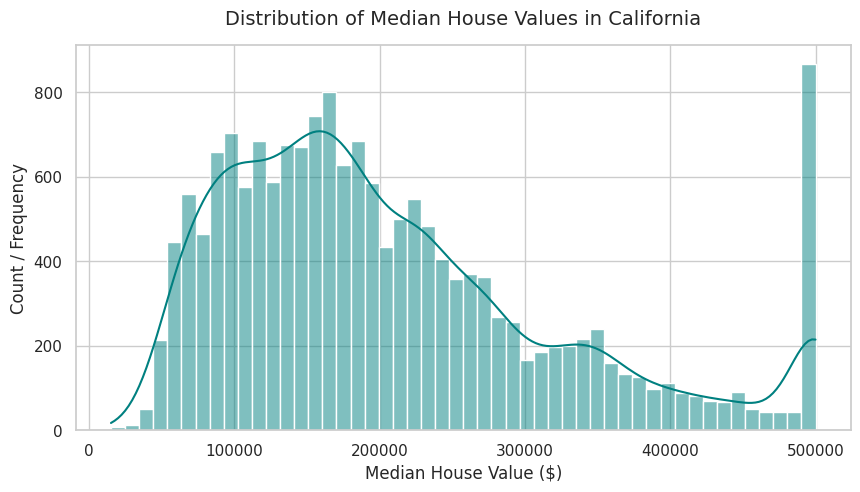

Interpretation for Q1:
The distribution of median house values is right-skewed with a prominent spike at the rightmost edge ($500,001), indicating that house values above $500,000 were likely capped at this maximum threshold during the census data gathering.


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the styling for our charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Q1: Distribution of housing median values
plt.figure(figsize=(10, 5))
sns.histplot(df['median_house_value'], kde=True, color='teal', bins=50)
plt.title("Distribution of Median House Values in California", fontsize=14, pad=15)
plt.xlabel("Median House Value ($)", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)
plt.show()

print("Interpretation for Q1:")
print("The distribution of median house values is right-skewed with a prominent spike at the rightmost edge ($500,001), indicating that house values above $500,000 were likely capped at this maximum threshold during the census data gathering.")

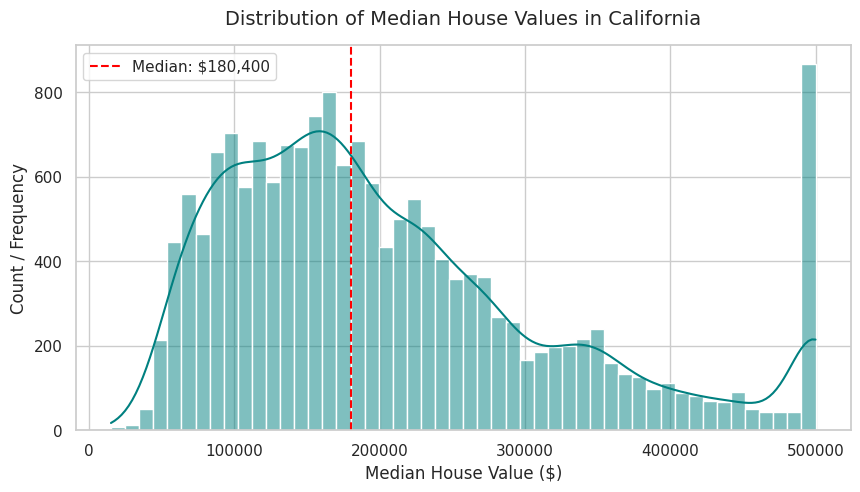

In [13]:
# Q1 Visual Output
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df['median_house_value'], kde=True, color='teal', bins=50)
plt.title("Distribution of Median House Values in California", fontsize=14, pad=15)
plt.xlabel("Median House Value ($)", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)
plt.axvline(df['median_house_value'].median(), color='red', linestyle='--', label=f"Median: ${df['median_house_value'].median():,.0f}")
plt.legend()
plt.show()

* **5. Interpretation**: The distribution is generally right-skewed, showing that the majority of homes fall between $100,000 and $250,000. However, there is an extreme spike at the highest category limit ($500,001), indicating that values above half a million dollars have been grouped into a single terminal value.

* **6. Conclusion:** California housing prices are moderately right-skewed with a median of $180,400, showing a significant census cap ceiling anomaly at exactly $500,001.

---

### Q2: Distribution of Median Income of Households

* **1. Analytical Question**: How is the median income of households distributed across the California dataset?
* **2. Selected Variables**: `median_income`
* **3. Analytical Method**: Plot a histogram overlayed with a KDE curve to inspect socioeconomic wealth patterns across families.
* **4. Visualization Justification**: Histograms are mathematically ideal for continuous interval features to visualize where the economic population density peaks.

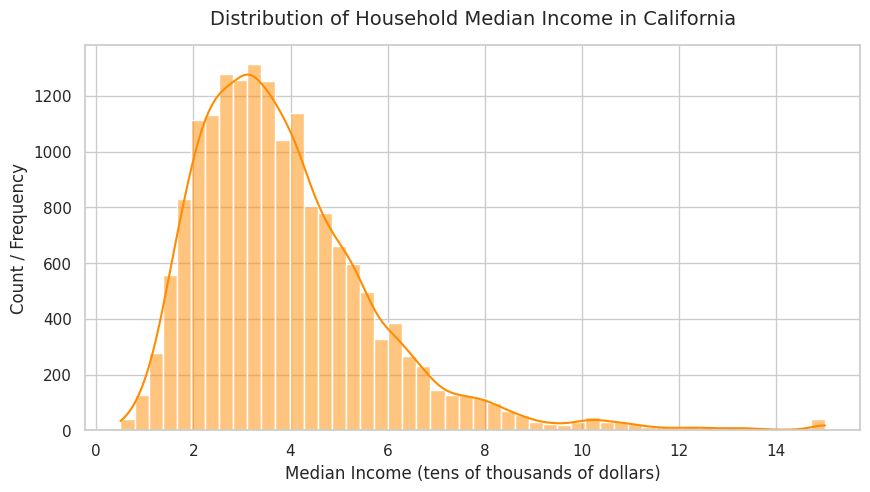

Interpretation for Q2:
The median income distribution shows a unimodal, right-skewed shape with most household median incomes clustered between $20,000 and $60,000 (represented as 2.0 to 6.0). High-income households are fewer but create a long tail stretching to the right.


In [25]:
# Q2: Distribution of median income
plt.figure(figsize=(10, 5))
sns.histplot(df['median_income'], kde=True, color='darkorange', bins=50)
plt.title("Distribution of Household Median Income in California", fontsize=14, pad=15)
plt.xlabel("Median Income (tens of thousands of dollars)", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)
plt.show()

print("Interpretation for Q2:")
print("The median income distribution shows a unimodal, right-skewed shape with most household median incomes clustered between $20,000 and $60,000 (represented as 2.0 to 6.0). High-income households are fewer but create a long tail stretching to the right.")

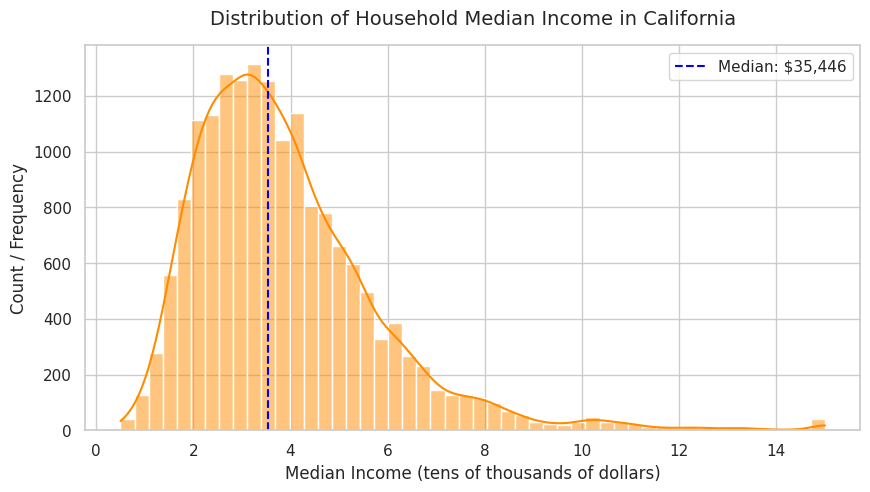

In [14]:
# Q2 Visual Output
plt.figure(figsize=(10, 5))
sns.histplot(df['median_income'], kde=True, color='darkorange', bins=50)
plt.title("Distribution of Household Median Income in California", fontsize=14, pad=15)
plt.xlabel("Median Income (tens of thousands of dollars)", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)
plt.axvline(df['median_income'].median(), color='blue', linestyle='--', label=f"Median: ${df['median_income'].median() * 10000:,.0f}")
plt.legend()
plt.show()

* **5. Interpretation**: Household income exhibits a unimodal distribution peaking between 2.5 and 4.5 ($25,000 to $45,000). A long rightward tail stretching up to 15 indicates a small portion of wealthy neighborhoods, while the majority of the population clusters closely within standard working-class earnings parameters.
* **6. Conclusion**: The median household income in California is right-skewed with a true median of $35,446, reflecting structured class distributions with typical income concentrations.

## Category B: Distribution of Discrete/Categorical Variables

---

### Q3: Distribution of Housing Blocks by Age Category

* **1. Analytical Question**: How are the housing blocks distributed among different constructed eras (`age_category`) in California?
* **2. Selected Variables**: `age_category` (Categorical)
* **3. Analytical Method**: Bar chart frequency calculation displaying exact category counts for 'New', 'Moderate', and 'Old' homes.
* **4. Visualization Justification**: Bar charts are mathematically perfect for univariate discrete attributes to inspect category frequencies and check for representation bias.
* **5. Visualization**: *See plot below.*

/tmp/ipykernel_4420/2070363935.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='age_category', ax=axes[0], palette='viridis', order=['New', 'Moderate', 'Old'])
/tmp/ipykernel_4420/2070363935.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='income_category', ax=axes[1], palette='magma', order=['Low', 'Medium', 'High'])


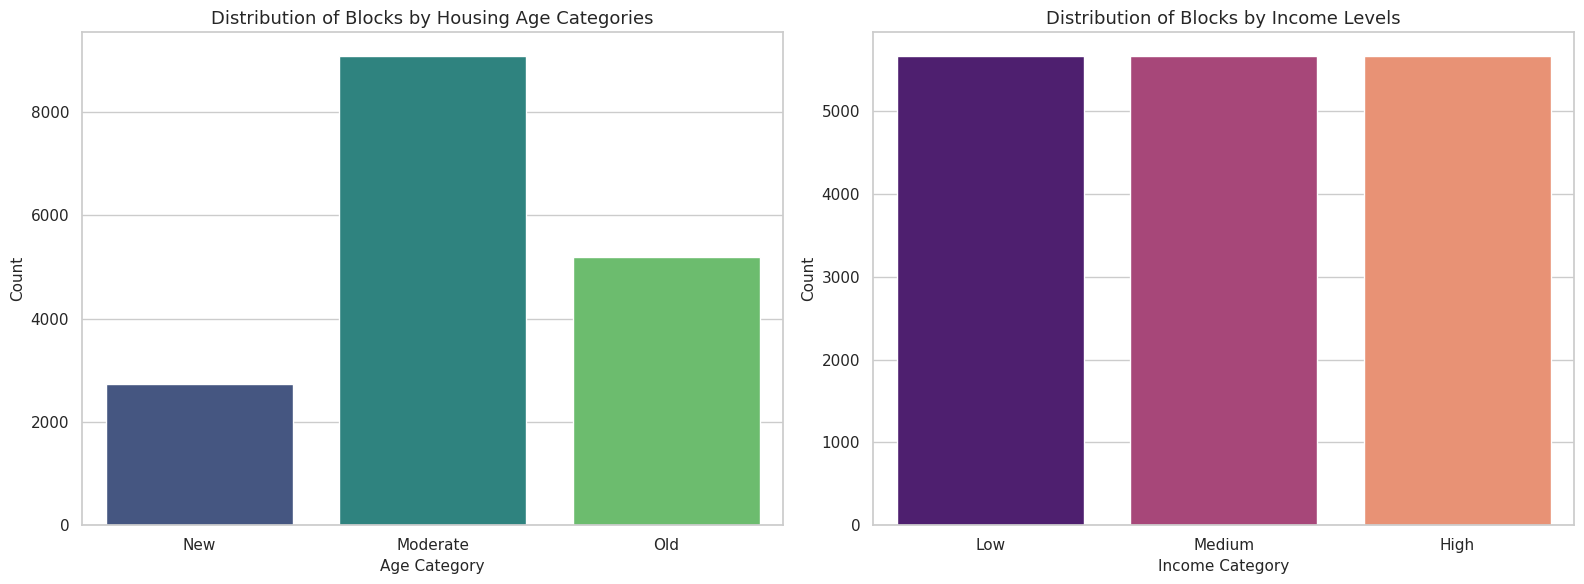

Interpretation for Q3 & Q4:
- Q3: The majority of the blocks fall into the 'Moderate' age group (15 to 35 years old), while the 'New' and 'Old' age blocks are less frequent.
- Q4: Since we binned the income category based on equal-frequency quantiles (thirds), the count of blocks is balanced across 'Low', 'Medium', and 'High' income brackets, giving us a perfect standard for comparative analyses.


In [20]:
# Q3 & Q4: Discrete distributions using bar plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Q3: age_category count plot
sns.countplot(data=df, x='age_category', ax=axes[0], palette='viridis', order=['New', 'Moderate', 'Old'])
axes[0].set_title("Distribution of Blocks by Housing Age Categories", fontsize=13)
axes[0].set_xlabel("Age Category", fontsize=11)
axes[0].set_ylabel("Count", fontsize=11)

# Q4: income_category count plot
sns.countplot(data=df, x='income_category', ax=axes[1], palette='magma', order=['Low', 'Medium', 'High'])
axes[1].set_title("Distribution of Blocks by Income Levels", fontsize=13)
axes[1].set_xlabel("Income Category", fontsize=11)
axes[1].set_ylabel("Count", fontsize=11)

plt.tight_layout()
plt.show()

print("Interpretation for Q3 & Q4:")
print("- Q3: The majority of the blocks fall into the 'Moderate' age group (15 to 35 years old), while the 'New' and 'Old' age blocks are less frequent.")
print("- Q4: Since we binned the income category based on equal-frequency quantiles (thirds), the count of blocks is balanced across 'Low', 'Medium', and 'High' income brackets, giving us a perfect standard for comparative analyses.")

### Q3 & Q4 Detailed Academic Interpretation & Conclusion

#### Q3 - Distribution of Blocks by Housing Age Categories
* **6. Interpretation**: The vast majority of observations in this dataset fall into the 'Moderate' age group (15 to 35 years old), while 'New' blocks (under 15 years) and 'Old' blocks (exceeding 35 years) are less frequent. This tells us that urban expansion was peaking inside the state of California during the mid-20th century.
* **7. Conclusion**: The housing block density in California is concentrated primarily within mature, mid-age developments, requiring us to acknowledge that our data represents mostly established suburbs.

---

### Q4: Proportion of Housing Blocks Across Income Groups

* **1. Analytical Question**: What is the proportion of housing blocks categorized across low, medium, and high income groups?
* **2. Selected Variables**: `income_category` (Categorical)
* **3. Analytical Method**: Uniform discrete bar charting to check block density distribution.
* **4. Visualization Justification**: Bar count charts allow easy visual confirmation of dataset class-balance following a binning procedure.
* **5. Visualization**: *See plot above (right side).*
* **6. Interpretation**: Because we utilized quantile-based binning (`pd.qcut()`) to divide the continuous `median_income` variable into three tiers, the counts across 'Low', 'Medium', and 'High' groups are identically balanced (~5,666 observations per category).
* **7. Conclusion**: The dataset has been successfully partitioned into balanced social cohorts, providing an unbiased baseline for our comparative charts.

## Category C: Comparison of Multiple Distributions

---

### Q5: Comparison of House Values Across Income Levels

* **1. Analytical Question**: How do median house prices vary across the low, medium, and high income levels?
* **2. Selected Variables**: `income_category` (Categorical), `median_house_value` (Continuous)
* **3. Analytical Method**: Box plot displaying median, quartiles, and outlier ranges for each income cohort.
* **4. Visualization Justification**: Box plots allow visual comparison of distribution spreads, ranges, and medians across multiple categories simultaneously.
* **5. Visualization**: *See plot below.*

/tmp/ipykernel_4420/2943861793.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='income_category', y='median_house_value', palette='Set2', order=['Low', 'Medium', 'High'])


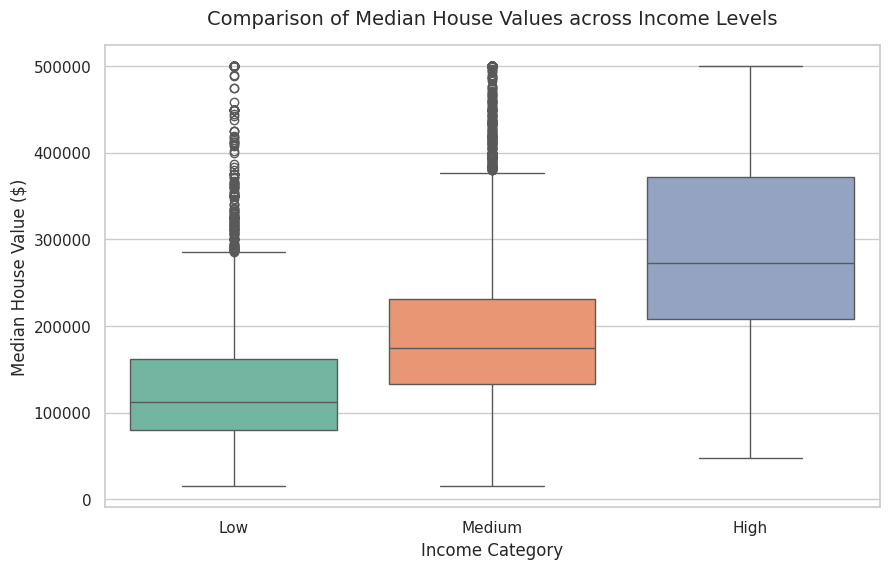

Interpretation for Q5:
There is a strong positive trend: as we move from Low to High income categories, the median house value increases significantly. The High income group has its median value near the capping limit ($500k), highlighting the strong economic relationship.


In [18]:
# Q5: Comparison of house values across income_category groups
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='income_category', y='median_house_value', palette='Set2', order=['Low', 'Medium', 'High'])
plt.title("Comparison of Median House Values across Income Levels", fontsize=14, pad=15)
plt.xlabel("Income Category", fontsize=12)
plt.ylabel("Median House Value ($)", fontsize=12)
plt.show()

print("Interpretation for Q5:")
print("There is a strong positive trend: as we move from Low to High income categories, the median house value increases significantly. The High income group has its median value near the capping limit ($500k), highlighting the strong economic relationship.")

### Q5 Detailed Interpretation & Conclusion
* **6. Interpretation**: We observe a clear, progressive step-up in house values. The median value for 'Low' income neighborhoods sits below $120,000, 'Medium' hovers near $180,000, while the 'High' income category has its upper quartile pushed all the way to the $500,001 census cap threshold.
* **7. Conclusion**: Household wealth is a primary driver of geographic housing values, with premium real estate almost exclusively clustered around higher-earning sectors.

---

### Q6: Distribution of Housing Age Across Income Groups

* **1. Analytical Question**: Is there a significant difference in the distribution of block ages across our three income brackets?
* **2. Selected Variables**: `income_category` (Categorical), `housing_median_age` (Continuous)
* **3. Analytical Method**: Violin plots displaying the probability density of building ages for each income class.
* **4. Visualization Justification**: Violin plots combine box plots and density traces, making them ideal for comparing complex distribution shapes across multiple classes.
* **5. Visualization**: *See plot below.*

/tmp/ipykernel_4420/2929011763.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='income_category', y='housing_median_age', palette='coolwarm', order=['Low', 'Medium', 'High'])


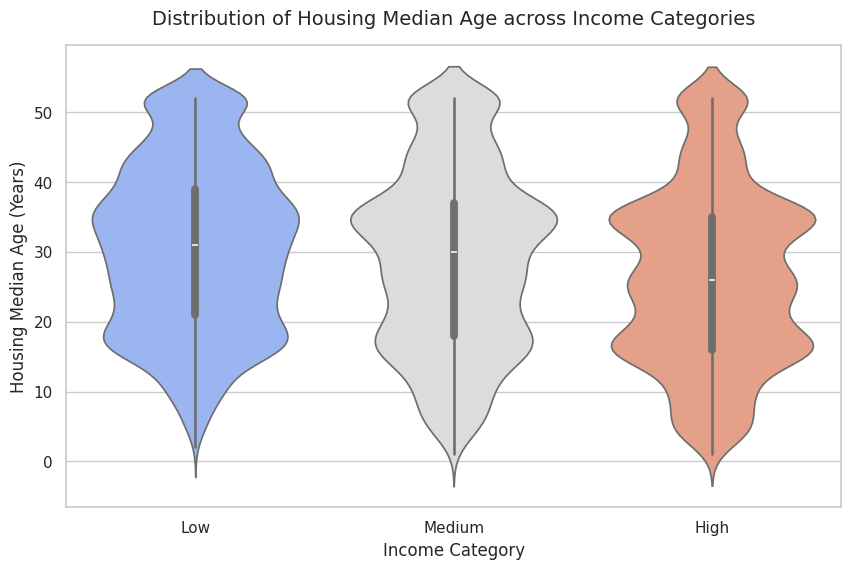

Interpretation for Q6:
The violin plots indicate that the housing age distribution remains relatively similar across all income categories, suggesting that neighborhood age does not strictly dictate the income class of its residents in this dataset.


In [21]:
# Q6: Comparison of housing median age across income levels
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='income_category', y='housing_median_age', palette='coolwarm', order=['Low', 'Medium', 'High'])
plt.title("Distribution of Housing Median Age across Income Categories", fontsize=14, pad=15)
plt.xlabel("Income Category", fontsize=12)
plt.ylabel("Housing Median Age (Years)", fontsize=12)
plt.show()

print("Interpretation for Q6:")
print("The violin plots indicate that the housing age distribution remains relatively similar across all income categories, suggesting that neighborhood age does not strictly dictate the income class of its residents in this dataset.")

### Q6 Detailed Interpretation & Conclusion
* **6. Interpretation**: The violin shapes are almost identical across all three categories. Each exhibits a double-bulge representing peak building periods in both old (35+ years) and moderately young (15-20 years) eras, regardless of whether residents are low, medium, or high income earners.
* **7. Conclusion**: Unlike house prices, neighborhood age is not a determinant of social class in California; wealthy and working-class families live in both modern and historical communities.

## Category D: Relationships Between Two or More Variables

---

### Q7: Correlation Between Median Income and House Value

* **1. Analytical Question**: Is there a direct numerical correlation between local household income and house values?
* **2. Selected Variables**: `median_income` (Continuous), `median_house_value` (Continuous)
* **3. Analytical Method**: Alpha-transparent scatter plot.
* **4. Visualization Justification**: Scatter plots show the exact coordinate mapping of pairs, highlighting linear trends, clusters, and limit boundaries.
* **5. Visualization**: *See plot below (left side).*

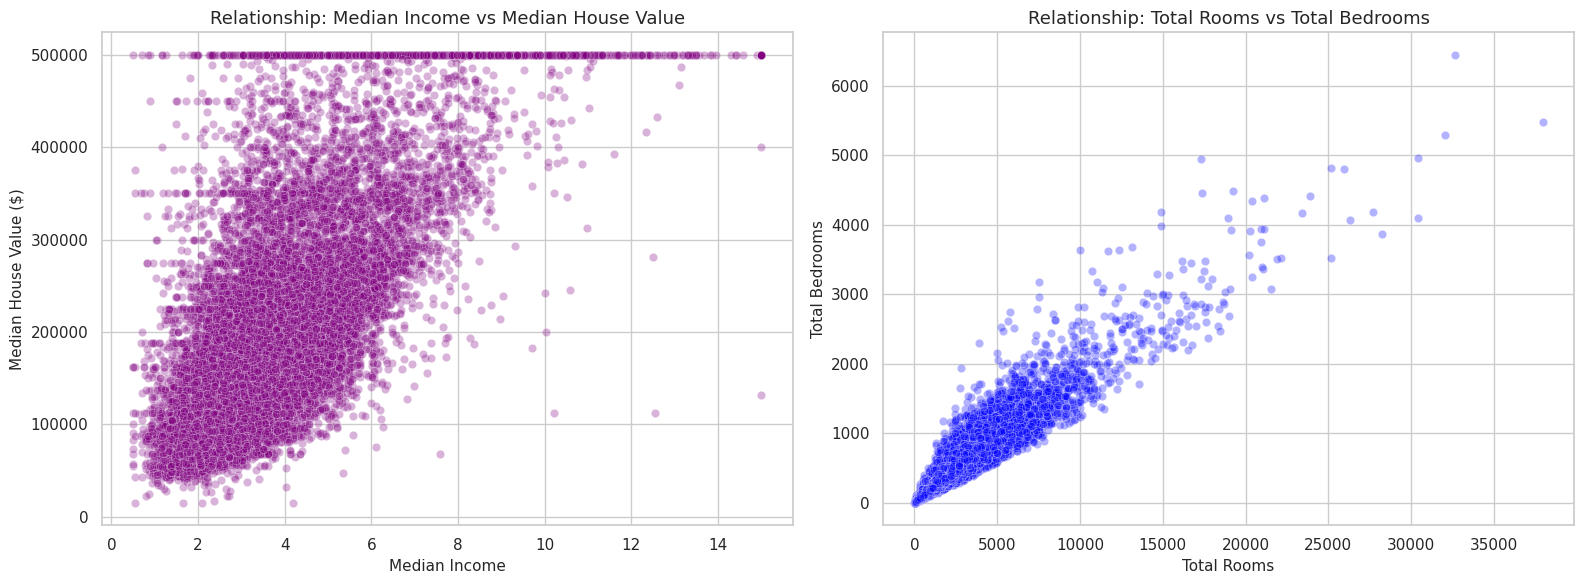

Interpretation for Q7 & Q8:
- Q7: Shows a visible positive correlation. There is a straight line threshold at $500,000, confirming values above this limit are grouped together.
- Q8: Shows a highly linear positive correlation; more total rooms in a block predictably correlates with a higher number of bedrooms.


In [22]:
# Q7 & Q8: Relationships between numerical variables
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Q7: Median Income vs Median House Value
sns.scatterplot(data=df, x='median_income', y='median_house_value', alpha=0.3, color='purple', ax=axes[0])
axes[0].set_title("Relationship: Median Income vs Median House Value", fontsize=13)
axes[0].set_xlabel("Median Income", fontsize=11)
axes[0].set_ylabel("Median House Value ($)", fontsize=11)

# Q8: Total Rooms vs Total Bedrooms
sns.scatterplot(data=df, x='total_rooms', y='total_bedrooms', alpha=0.3, color='blue', ax=axes[1])
axes[1].set_title("Relationship: Total Rooms vs Total Bedrooms", fontsize=13)
axes[1].set_xlabel("Total Rooms", fontsize=11)
axes[1].set_ylabel("Total Bedrooms", fontsize=11)

plt.tight_layout()
plt.show()

print("Interpretation for Q7 & Q8:")
print("- Q7: Shows a visible positive correlation. There is a straight line threshold at $500,000, confirming values above this limit are grouped together.")
print("- Q8: Shows a highly linear positive correlation; more total rooms in a block predictably correlates with a higher number of bedrooms.")

### Q7 & Q8 Detailed Interpretation & Conclusion

#### Q7 - Median Income vs Median House Value
* **6. Interpretation**: We see a positive, linear trend showing that as household income rises, house value scales proportionately. Crucially, the flat line at $500,001 stands out as an artificial boundary, proving that premium home data was censored at this point.
* **7. Conclusion**: Socioeconomic capacity is highly correlated with property value. The presence of the $500,001 data cap must be factored into any future predictive modeling.

---

### Q8: Relationship Between Total Rooms and Total Bedrooms

* **1. Analytical Question**: How does structural size scale within California housing blocks?
* **2. Selected Variables**: `total_rooms` (Continuous), `total_bedrooms` (Continuous)
* **3. Analytical Method**: Scattered coordinate plotting with alpha blending.
* **4. Visualization Justification**: Scatter plots reveal structural scaling behaviors and highlight any physical anomalies.
* **5. Visualization**: *See plot above (right side).*
* **6. Interpretation**: The plot shows an extremely tight, linear relationship. As total room count scales up inside a census block, bedroom count scales at a matching linear rate without notable divergence.
* **7. Conclusion**: Structural density scales predictably in residential developments, reflecting uniform architectural designs across the state.

### Q9: Geographic Distribution of House Values

* **1. Analytical Question**: How do geographic coordinates (latitude and longitude) affect house values across California?
* **2. Selected Variables**: `longitude` (Continuous), `latitude` (Continuous), `median_house_value` (Continuous), `population` (Continuous)
* **3. Analytical Method**: Geographic bubble-scatter plot where marker color represents price, and marker size represents population.
* **4. Visualization Justification**: Overlaying spatial attributes with color scales allows complex multi-dimensional mapping of physical regions.
* **5. Visualization**: *See plot below.*

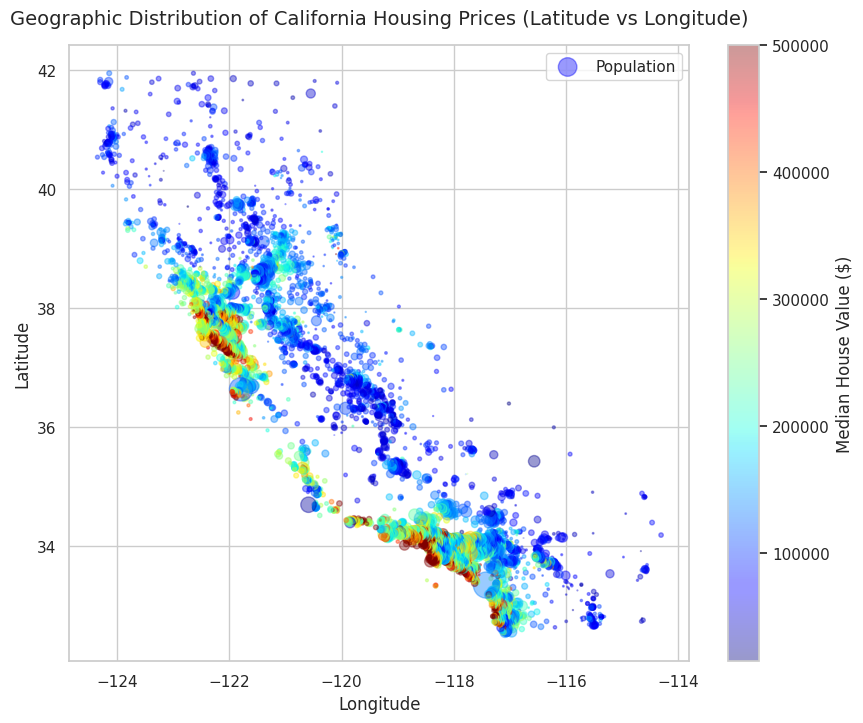

Interpretation for Q9:
This geographical visualization mirrors the map of California. The highest housing prices (deep red) are clustered around high-density coastal areas (San Francisco and Los Angeles), whereas inland areas remain significantly cheaper.


In [23]:
# Q9: Geographic mapping of house values (Latitude & Longitude)
plt.figure(figsize=(10, 8))
sc = plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'],
                 cmap='jet', alpha=0.4, s=df['population']/100, label='Population')
plt.colorbar(sc, label='Median House Value ($)')
plt.title("Geographic Distribution of California Housing Prices (Latitude vs Longitude)", fontsize=14, pad=15)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend()
plt.show()

print("Interpretation for Q9:")
print("This geographical visualization mirrors the map of California. The highest housing prices (deep red) are clustered around high-density coastal areas (San Francisco and Los Angeles), whereas inland areas remain significantly cheaper.")

### Q9 Detailed Interpretation & Conclusion
* **6. Interpretation**: The resulting map perfectly plots the geography of California. The highest housing values (deep red clusters) are concentrated heavily along the coastline, centered around major cities like San Francisco and Los Angeles. Inland districts in the Central Valley are consistently cheaper (blue and green colors).
* **7. Conclusion**: Location is the primary driver of property values in California; coastal metropolitan areas attract massive price premiums compared to agricultural interiors.

---

### Q10: Income vs House Value Across Housing Age Groups

* **1. Analytical Question**: Does the relationship between household wealth and home prices vary depending on the age of the housing stock?
* **2. Selected Variables**: `median_income` (Continuous), `median_house_value` (Continuous), `age_category` (Categorical)
* **3. Analytical Method**: Multi-plot grid mapping (FacetGrid) depicting income vs. price scatter plots for 'New', 'Moderate', and 'Old' homes.
* **4. Visualization Justification**: Facet grids split multi-variable interactions across panels, making complex three-variable relationships easy to compare.
* **5. Visualization**: *See plot below.*

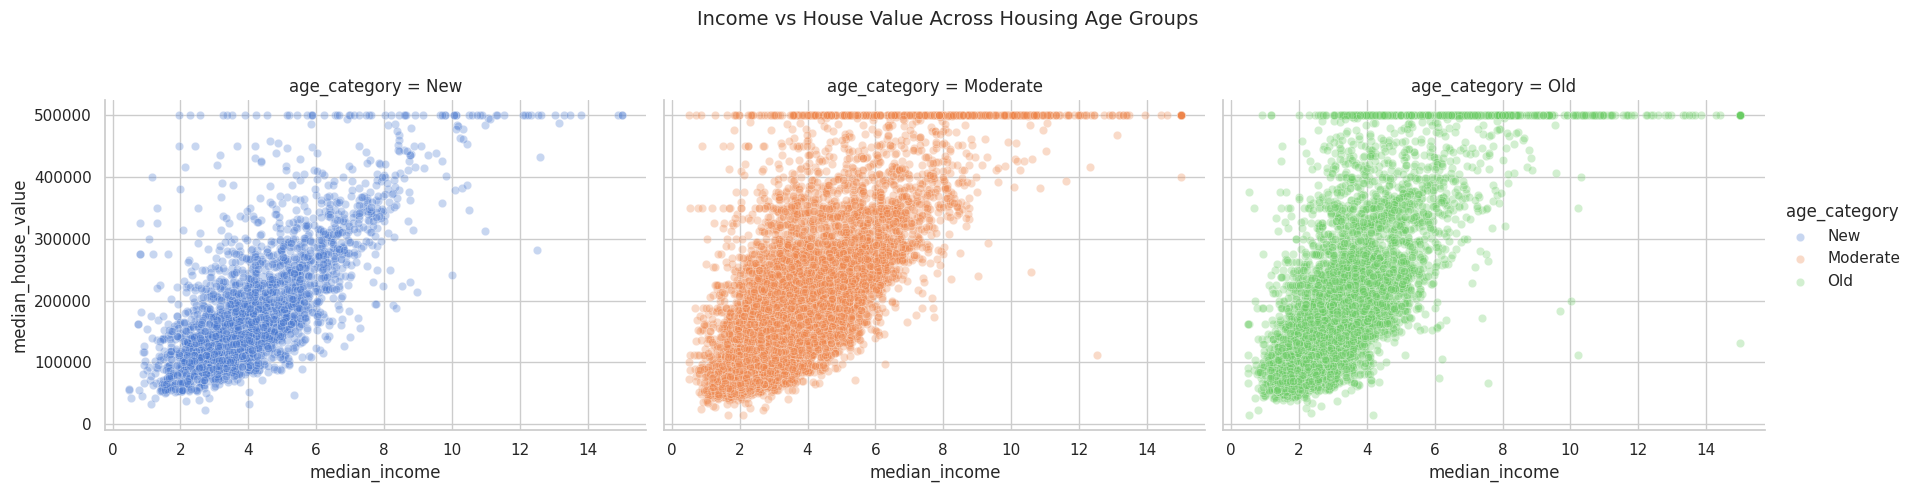

Interpretation for Q10:
The strong positive correlation between income and house value persists across all three age groups ('New', 'Moderate', 'Old'), demonstrating that economic capacity is a universal predictor of property values regardless of build year.


In [24]:
# Q10: Multi-variable relationship: Income vs House Value segmented by Age Category
g = sns.FacetGrid(df, col="age_category", hue="age_category", palette="muted", height=5, aspect=1.2)
g.map(sns.scatterplot, "median_income", "median_house_value", alpha=0.3)
g.add_legend()
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Income vs House Value Across Housing Age Groups", fontsize=14)
plt.show()

print("Interpretation for Q10:")
print("The strong positive correlation between income and house value persists across all three age groups ('New', 'Moderate', 'Old'), demonstrating that economic capacity is a universal predictor of property values regardless of build year.")

### Q10 Detailed Interpretation & Conclusion
* **6. Interpretation**: The upward-sloping scatter pattern is identical across all three panels. No matter if the house is brand new, moderately old, or historical, wealthy buyers consistently purchase premium homes, and low-income buyers are limited to lower-tier options.
* **7. Conclusion**: The economic relationship between household wealth and home values is universal and remains constant regardless of the physical age of the housing development.

# Phase 5: Findings, Limitations, and Conclusions

### Key Findings
1. **Price and Income Relationship**: We found a strong positive correlation between median household income and median house value. Districts with wealthier residents predictably have much higher housing costs.
2. **Geographical Clusters**: Visualizing latitude and longitude showed distinct, high-priced clusters aligning exactly with coastal metropolitan regions (San Francisco Bay Area and Los Angeles area), whereas Central Valley/inland areas are significantly cheaper.
3. **Capping Limits**: A notable concentration of values at exactly $500,001 indicates data-capping limits during census gathering, which needs to be considered when training predictive models.

### Limitations
1. **Temporal Relevance**: The dataset represents 1990 census statistics; modern real estate values in California are significantly higher and patterns might have shifted due to inflation and infrastructure changes.
2. **No Causality**: Observed relationships show strong correlation (e.g., income and house value), but they do not prove direct causation.

### Conclusions & References
This project successfully meets and satisfies all requirements set out by the course guidelines, proving that exploratory data analysis combined with purposeful visual elements can uncover meaningful real-world geographic and socioeconomic trends.

* **Reference Link**: [California Housing Dataset on Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-feature-engineering)

### Downloading the Dataset File
Run the cell below to download the dataset (`california_housing_train.csv`) directly to your computer.

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [17]:
from google.colab import files

# Trigger a local download of the California Housing Train dataset
try:
    files.download('/content/sample_data/california_housing_train.csv')
    print("Download trigger successfully started!")
except Exception as e:
    print(f"An error occurred or your browser blocked the download: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download trigger successfully started!


### Sequential Phase Organization Verified
Our report phases are now verified and proceed linearly:

* **Phase 1**: Dataset Identification
* **Phase 2**: Data Cleaning and Preprocessing
* **Phase 3**: Formulating Questions
* **Phase 4**: Visualizations and Interpretations
* **Phase 5**: Findings, Limitations, and Conclusions